# 05. Real + Imaginary Combined MP-PCA — 3-Core Parallel

`02_Add_noise_Open_QSM_FULL_VOLUME_REVISED.ipynb`에서 생성한
**5-echo noisy complex GRE**를 Real과 Imaginary 성분으로 분리한 뒤,
두 성분을 채널 방향으로 결합하여 하나의 MP-PCA를 수행한다.

5-echo 데이터의 Combined 입력은 다음과 같다.

```text
[R1, R2, R3, R4, R5, I1, I2, I3, I4, I5]
```

즉 각 spatial patch에서 **Real 5 + Imaginary 5 = 10 features**를 동시에 사용한다.

이번 버전은 서버 CPU 3개를 활용하기 위해
**Noise 10%, 30%, 50%를 각각 독립 프로세스에서 동시에 처리**한다.

```text
Process 1 → Noise 10% Combined MP-PCA
Process 2 → Noise 30% Combined MP-PCA
Process 3 → Noise 50% Combined MP-PCA
```

실험 원칙:

- 입력: `(X, Y, Z, 5)` noisy complex GRE
- Combined feature: `(X, Y, Z, 10)`
- Patch radius = 3 → `7 × 7 × 7`
- Patch voxels = 343
- **Brain mask는 denoising에 사용하지 않음**
- **전체 volume denoising**
- Brain mask는 향후 최종 평가 ROI용으로만 저장
- Real/Imaginary의 음수 값을 보존하기 위해 `localpca_dn.py`의 `mppca()` 사용


In [1]:
import os
import time
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
from pathlib import Path
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed


/home/std-202102478/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-_36xousw because there was an issue with the default path (/home/std-202102478/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


### 환경설정

입력 noisy data:

`./data/noisy_data/`

- `qsm_siemens_monopolar_noisy_10.npz`
- `qsm_siemens_monopolar_noisy_30.npz`
- `qsm_siemens_monopolar_noisy_50.npz`

출력:

`./data/denoised/real_imag_combined/`

서버 실행 시 이 notebook과 함께 `localpca_dn.py`가
`~/workspace`에서 import 가능해야 한다.

3-core 병렬화는 noise level 단위로 수행한다.
각 worker가 자기 `.npz` 파일을 직접 읽고 Combined MP-PCA를 수행한 뒤
결과 `.mat` 파일을 직접 저장한다.


In [2]:
NOISE_LEVELS = [10, 30, 50]

PATCH_R = 3
N_ECHO = 5
N_FEATURE = N_ECHO * 2
N_WORKERS = 3

NOISY_DIR = Path("./data/noisy_data").resolve()
OUT_DIR = Path("./data/denoised/real_imag_combined").resolve()

OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Noisy directory :", NOISY_DIR)
print("Output directory:", OUT_DIR)
print("Echoes          :", N_ECHO)
print("Combined feature:", N_FEATURE)
print("Patch radius    :", PATCH_R)
print("Parallel workers:", N_WORKERS)
print(
    "Patch size      :",
    f"{2 * PATCH_R + 1} x {2 * PATCH_R + 1} x {2 * PATCH_R + 1}"
)


Noisy directory : /home/std-202102478/workspace/data/noisy_data
Output directory: /home/std-202102478/workspace/data/denoised/real_imag_combined
Echoes          : 5
Combined feature: 10
Patch radius    : 3
Parallel workers: 3
Patch size      : 7 x 7 x 7


### 1. 입력 파일 확인

부모 프로세스에서는 세 noise level의 입력 파일 존재 여부만 확인한다.

각 worker가 자기 noise level의 `.npz`를 직접 읽도록 하여
큰 4D 배열을 프로세스 간에 전달하지 않는다.


In [3]:
input_paths = {}

for noise_level in NOISE_LEVELS:
    noisy_path = (
        NOISY_DIR /
        f"qsm_siemens_monopolar_noisy_{noise_level}.npz"
    )

    if not noisy_path.exists():
        raise FileNotFoundError(
            f"Noise 파일을 찾을 수 없습니다: {noisy_path}\n"
            "먼저 02_Add_noise_Open_QSM_FULL_VOLUME_REVISED.ipynb를 실행하세요."
        )

    input_paths[noise_level] = noisy_path
    print(f"{noise_level}% 입력 확인 -> {noisy_path}")

print("\n모든 입력 파일 확인 완료")


10% 입력 확인 -> /home/std-202102478/workspace/data/noisy_data/qsm_siemens_monopolar_noisy_10.npz
30% 입력 확인 -> /home/std-202102478/workspace/data/noisy_data/qsm_siemens_monopolar_noisy_30.npz
50% 입력 확인 -> /home/std-202102478/workspace/data/noisy_data/qsm_siemens_monopolar_noisy_50.npz

모든 입력 파일 확인 완료


### 2. Real + Imaginary Combined MP-PCA worker

각 worker는 하나의 noise level 전체를 담당한다.

처리 순서:

1. noisy complex GRE `(X,Y,Z,5)` 로드
2. Real `(X,Y,Z,5)` / Imaginary `(X,Y,Z,5)` 분리
3. `[Real 5 | Imag 5]` 방향으로 결합 → `(X,Y,Z,10)`
4. 전체 volume에 MP-PCA 수행
5. 앞 5 features를 Real, 뒤 5 features를 Imaginary로 분리
6. `Real + j·Imag`로 complex 재결합
7. 최종 `.mat` 저장

`mask_brain`은 결과 파일에 저장하지만 **MP-PCA 함수에는 전달하지 않는다.**


In [4]:
def run_combined_worker(
    noise_level,
    noisy_path_str,
    out_dir_str,
    patch_r,
    n_echo
):
    import os
    import time
    import numpy as np
    import scipy.io as sio
    from pathlib import Path

    # Real/Imaginary의 음수 값을 보존하는 custom MP-PCA
    from localpca_dn import mppca

    start_time = time.time()

    noisy_path = Path(noisy_path_str)
    out_dir = Path(out_dir_str)
    out_dir.mkdir(parents=True, exist_ok=True)

    print(
        f"[PID {os.getpid()}] START | Noise {noise_level}% | "
        f"file={noisy_path.name}",
        flush=True
    )

    data = np.load(noisy_path, allow_pickle=False)

    noisy_complex = data["noisy_complex"].astype(np.complex64)
    mask = data["mask_brain"].astype(bool)

    if noisy_complex.ndim != 4:
        raise ValueError(
            f"{noise_level}% noisy_complex는 4D여야 합니다. "
            f"현재 shape={noisy_complex.shape}"
        )

    if noisy_complex.shape[-1] != n_echo:
        raise ValueError(
            f"{noise_level}% 데이터는 {n_echo} echoes를 예상합니다. "
            f"실제={noisy_complex.shape[-1]}"
        )

    if mask.shape != noisy_complex.shape[:3]:
        raise ValueError(
            f"{noise_level}% mask shape {mask.shape} != "
            f"spatial shape {noisy_complex.shape[:3]}"
        )

    # metadata
    noise_ratio = float(data["noise_ratio"])
    sigma = float(data["sigma"])
    seed = int(data["seed"])
    overall_mean = float(data["overall_mean"])

    echo_times = (
        data["echo_times"].astype(np.float64)
        if "echo_times" in data.files
        else np.full(n_echo, np.nan, dtype=np.float64)
    )

    field_strength = (
        float(data["field_strength"])
        if "field_strength" in data.files
        else np.nan
    )

    # ---------------------------------------------------------
    # Real 5 + Imag 5 -> Combined 10 features
    # ---------------------------------------------------------
    noisy_real = noisy_complex.real.astype(np.float32)
    noisy_imag = noisy_complex.imag.astype(np.float32)

    combined_input = np.concatenate(
        [noisy_real, noisy_imag],
        axis=-1
    ).astype(np.float32)

    del noisy_complex, noisy_real, noisy_imag

    if combined_input.shape[-1] != 2 * n_echo:
        raise ValueError(
            f"{noise_level}% combined feature 수 오류: "
            f"{combined_input.shape[-1]} != {2 * n_echo}"
        )

    print(
        f"[PID {os.getpid()}] COMBINED MP-PCA | "
        f"Noise {noise_level}% | shape={combined_input.shape} | "
        f"patch_radius={patch_r} | mask=NOT_USED | ROI=FULL_VOLUME",
        flush=True
    )

    # 핵심: mask 없이 full-volume MP-PCA
    deno_combined = mppca(
        combined_input,
        patch_radius=patch_r
    ).astype(np.float32)

    if deno_combined.shape != combined_input.shape:
        raise ValueError(
            f"{noise_level}% denoised shape {deno_combined.shape} "
            f"!= input {combined_input.shape}"
        )

    del combined_input

    # ---------------------------------------------------------
    # Real / Imaginary 분리 및 complex 재결합
    # ---------------------------------------------------------
    deno_real = deno_combined[..., :n_echo].astype(np.float32)
    deno_imag = deno_combined[..., n_echo:].astype(np.float32)

    deno_complex = (
        deno_real.astype(np.complex64)
        + 1j * deno_imag.astype(np.complex64)
    ).astype(np.complex64)

    output_path = (
        out_dir /
        f"denoised_real_imag_combined_{noise_level}_r{patch_r}.mat"
    )

    save_data = {
        "deno_combined": deno_combined,
        "deno_real": deno_real,
        "deno_imag": deno_imag,
        "deno_complex": deno_complex,
        "mask_brain": mask.astype(np.uint8),
        "noise_level": np.int32(noise_level),
        "noise_ratio": np.float32(noise_ratio),
        "sigma": np.float32(sigma),
        "seed": np.int32(seed),
        "overall_mean": np.float32(overall_mean),
        "patch_radius": np.int32(patch_r),
        "n_echo": np.int32(n_echo),
        "n_feature": np.int32(2 * n_echo),
        "echo_times": np.asarray(echo_times, dtype=np.float64),
        "field_strength": np.float32(field_strength),
        "denoise_region": "full_volume",
        "mask_usage": "evaluation_only",
        "parallel_workers": np.int32(3),
        "method": "real_imag_combined_mppca",
    }

    sio.savemat(
        output_path,
        save_data,
        do_compression=True
    )

    elapsed = time.time() - start_time

    print(
        f"[PID {os.getpid()}] DONE | Noise {noise_level}% | "
        f"{elapsed / 60:.2f} min | {output_path.name}",
        flush=True
    )

    return {
        "noise_level": int(noise_level),
        "output_path": str(output_path),
        "elapsed_sec": float(elapsed),
        "pid": int(os.getpid()),
    }


### 3. 10% / 30% / 50%를 3코어 동시 실행

Linux 서버에서 `fork` multiprocessing context를 사용한다.

```text
Worker 1 → Noise 10% Combined MP-PCA
Worker 2 → Noise 30% Combined MP-PCA
Worker 3 → Noise 50% Combined MP-PCA
```

서버 제출 조건:

- `-c 3`
- `OMP_NUM_THREADS=1`
- `OPENBLAS_NUM_THREADS=1`
- `MKL_NUM_THREADS=1`

따라서 3개 worker가 각각 한 CPU core를 중심으로 사용한다.


In [5]:
parallel_start = time.time()
worker_results = {}

ctx = mp.get_context("fork")

print("=" * 70)
print("3-Core Parallel Real + Imag Combined MP-PCA 시작")
print(f"Noise levels : {NOISE_LEVELS}")
print(f"Workers      : {N_WORKERS}")
print(f"Echoes       : {N_ECHO}")
print(f"Features     : {N_FEATURE}")
print(f"Patch radius : {PATCH_R}")
print("=" * 70)

with ProcessPoolExecutor(
    max_workers=N_WORKERS,
    mp_context=ctx
) as executor:

    future_to_level = {
        executor.submit(
            run_combined_worker,
            noise_level,
            str(input_paths[noise_level]),
            str(OUT_DIR),
            PATCH_R,
            N_ECHO
        ): noise_level
        for noise_level in NOISE_LEVELS
    }

    for future in as_completed(future_to_level):
        noise_level = future_to_level[future]

        try:
            result = future.result()
            worker_results[noise_level] = result

            print(
                f"MAIN: {noise_level}% 완료 | "
                f"PID={result['pid']} | "
                f"{result['elapsed_sec'] / 60:.2f} min"
            )

        except Exception as e:
            print(
                f"MAIN: {noise_level}% FAILED -> {repr(e)}"
            )
            raise

parallel_elapsed = time.time() - parallel_start

print("\n" + "=" * 70)
print("모든 noise level Combined MP-PCA 병렬 처리 완료")
print(f"전체 wall time: {parallel_elapsed / 60:.2f} min")
print("=" * 70)

for noise_level in sorted(worker_results):
    print(worker_results[noise_level])


3-Core Parallel Real + Imag Combined MP-PCA 시작
Noise levels : [10, 30, 50]
Workers      : 3
Echoes       : 5
Features     : 10
Patch radius : 3


[PID 91] START | Noise 50% | file=qsm_siemens_monopolar_noisy_50.npz

[PID 90] START | Noise 30% | file=qsm_siemens_monopolar_noisy_30.npz

[PID 89] START | Noise 10% | file=qsm_siemens_monopolar_noisy_10.npz

[PID 91] COMBINED MP-PCA | Noise 50% | shape=(176, 256, 144, 10) | patch_radius=3 | mask=NOT_USED | ROI=FULL_VOLUME

[PID 90] COMBINED MP-PCA | Noise 30% | shape=(176, 256, 144, 10) | patch_radius=3 | mask=NOT_USED | ROI=FULL_VOLUME

... (2 outputs left out)

[PID 90] DONE | Noise 30% | 15.51 min | denoised_real_imag_combined_30_r3.mat

MAIN: 50% 완료 | PID=91 | 15.51 min
MAIN: 30% 완료 | PID=90 | 15.51 min


[PID 89] DONE | Noise 10% | 16.23 min | denoised_real_imag_combined_10_r3.mat

MAIN: 10% 완료 | PID=89 | 16.23 min

모든 noise level Combined MP-PCA 병렬 처리 완료
전체 wall time: 16.24 min
{'noise_level': 10, 'output_path': '/home/std-202102478/workspace/data/denoised/real_imag_combined/denoised_real_imag_combined_10_r3.mat', 'elapsed_sec': 973.6095533370972, 'pid': 89}
{'noise_level': 30, 'output_path': '/home/std-202102478/workspace/data/denoised/real_imag_combined/denoised_real_imag_combined_30_r3.mat', 'elapsed_sec': 930.7698237895966, 'pid': 90}
{'noise_level': 50, 'output_path': '/home/std-202102478/workspace/data/denoised/real_imag_combined/denoised_real_imag_combined_50_r3.mat', 'elapsed_sec': 930.5820188522339, 'pid': 91}


### 4. 저장 결과 확인

각 worker가 자기 noise level의 최종 결과를 직접 저장한다.

출력 파일:

- `denoised_real_imag_combined_10_r3.mat`
- `denoised_real_imag_combined_30_r3.mat`
- `denoised_real_imag_combined_50_r3.mat`

각 파일에는 Combined 10-feature 결과와
분리된 Real / Imaginary / complex 결과가 함께 저장된다.


In [6]:
output_paths = {}

for noise_level in NOISE_LEVELS:
    output_path = (
        OUT_DIR /
        f"denoised_real_imag_combined_{noise_level}_r{PATCH_R}.mat"
    )

    if not output_path.exists():
        raise FileNotFoundError(
            f"{noise_level}% 결과 파일이 생성되지 않았습니다: {output_path}"
        )

    output_paths[noise_level] = output_path

    size_mb = output_path.stat().st_size / (1024 ** 2)

    print(
        f"{noise_level}% 결과 확인 | "
        f"{output_path.name} | {size_mb:.1f} MB"
    )


10% 결과 확인 | denoised_real_imag_combined_10_r3.mat | 695.6 MB
30% 결과 확인 | denoised_real_imag_combined_30_r3.mat | 694.7 MB
50% 결과 확인 | denoised_real_imag_combined_50_r3.mat | 694.5 MB


### 5. 결과 시각화

Clean reference를 이 notebook에서 직접 사용하지 않고,
noise level 하나씩 입력과 denoised 결과를 다시 읽어 확인한다.

표시 항목:

- Noisy Magnitude
- Denoised Magnitude
- Removed = `Noisy - Denoised`

`Removed`는 최종 error map이 아니라
Combined MP-PCA가 noisy 입력에서 제거한 성분을 보기 위한 시각화이다.

최종 PSNR / SSIM / NRMSE / HFEN은 별도 평가 단계에서
clean reference와 `mask_brain`을 사용한다.


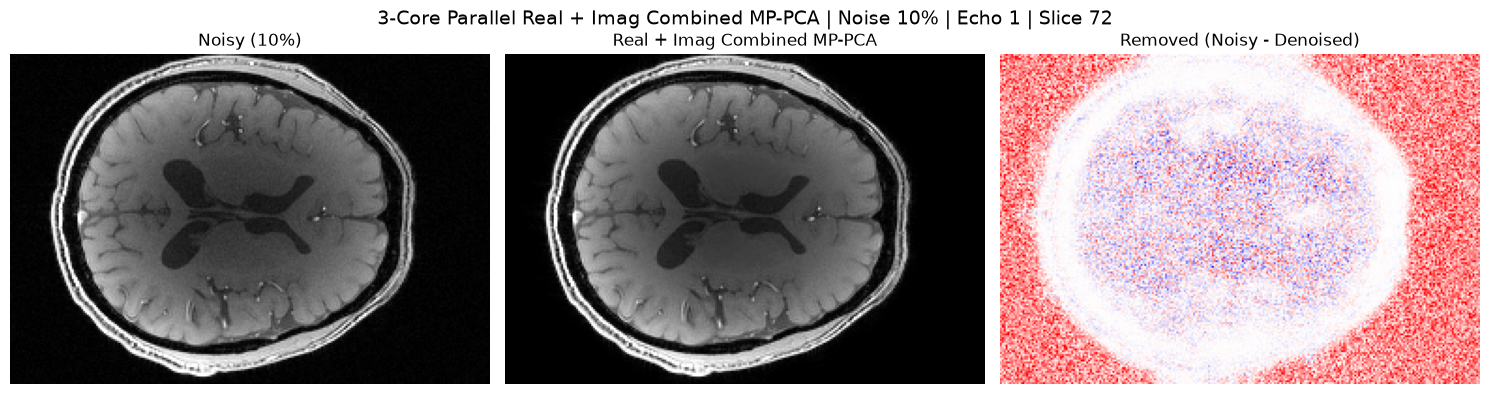

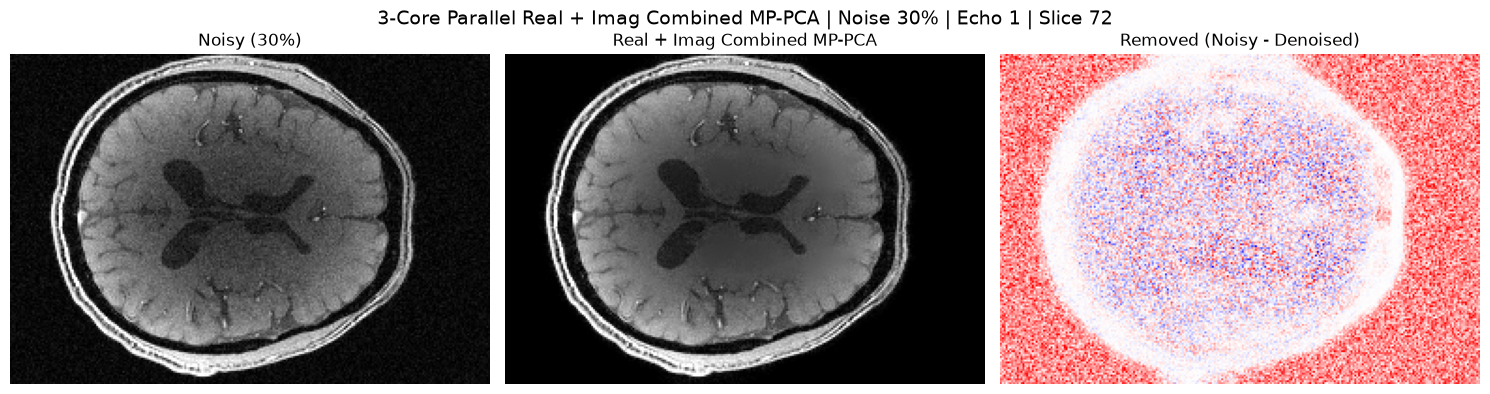

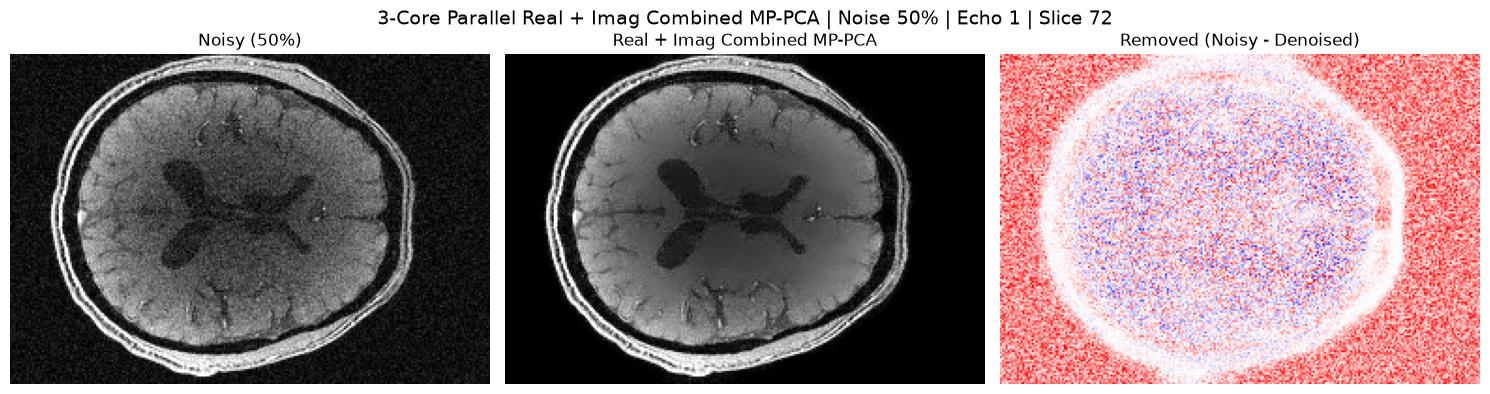

In [7]:
echo_idx = 0

for noise_level in NOISE_LEVELS:
    noisy_npz = np.load(
        input_paths[noise_level],
        allow_pickle=False
    )
    noisy_complex = noisy_npz["noisy_complex"].astype(np.complex64)

    mat = sio.loadmat(output_paths[noise_level])
    deno_complex = mat["deno_complex"].astype(np.complex64)

    if deno_complex.shape != noisy_complex.shape:
        raise ValueError(
            f"{noise_level}% visualization shape mismatch: "
            f"{deno_complex.shape} != {noisy_complex.shape}"
        )

    noisy_mag = np.abs(noisy_complex).astype(np.float32)
    deno_mag = np.abs(deno_complex).astype(np.float32)

    slice_idx = noisy_mag.shape[2] // 2

    noisy_2d = noisy_mag[:, :, slice_idx, echo_idx]
    deno_2d = deno_mag[:, :, slice_idx, echo_idx]
    removed_2d = noisy_2d - deno_2d

    vmin, vmax = np.percentile(noisy_2d, (1, 99))

    dv = float(np.percentile(np.abs(removed_2d), 99))
    dv = max(dv, 1e-8)

    fig, ax = plt.subplots(1, 3, figsize=(15, 4))

    ax[0].imshow(
        noisy_2d,
        cmap="gray",
        vmin=vmin,
        vmax=vmax
    )
    ax[0].set_title(f"Noisy ({noise_level}%)")

    ax[1].imshow(
        deno_2d,
        cmap="gray",
        vmin=vmin,
        vmax=vmax
    )
    ax[1].set_title("Real + Imag Combined MP-PCA")

    ax[2].imshow(
        removed_2d,
        cmap="bwr",
        vmin=-dv,
        vmax=dv
    )
    ax[2].set_title("Removed (Noisy - Denoised)")

    for a in ax:
        a.axis("off")

    fig.suptitle(
        f"3-Core Parallel Real + Imag Combined MP-PCA | "
        f"Noise {noise_level}% | Echo {echo_idx + 1} | Slice {slice_idx}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

    del noisy_complex, deno_complex, noisy_mag, deno_mag, mat


### 완료

세 noise level을 3개 worker에서 동시에 처리하고,
각 결과가 `./data/denoised/real_imag_combined/`에 저장되면 완료이다.

현재 Combined feature 구조:

```text
343 spatial voxels × 10 features
= 7 × 7 × 7 patch × (Real 5 + Imag 5)
```


In [8]:
print("05_Real_Imag_Combined_3 완료")
print("Output directory:", OUT_DIR)
print("Parallel workers:", N_WORKERS)


05_Real_Imag_Combined_3 완료
Output directory: /home/std-202102478/workspace/data/denoised/real_imag_combined
Parallel workers: 3
